# 02b — Coefficient de température du modérateur

**Question** : quand l'eau du circuit primaire s'échauffe, la réactivité augmente-t-elle ou diminue-t-elle ?

La réponse détermine la **stabilité naturelle** du réacteur. Si un échauffement de l'eau fait baisser la
réactivité (coefficient **négatif**), toute hausse de puissance s'auto-limite : plus de puissance, eau plus chaude,
moins de réactivité, retour à l'équilibre. Avec un coefficient **positif**, la même hausse s'auto-entretiendrait.
C'est pourquoi un REP doit fonctionner en puissance avec un coefficient de température du modérateur (en anglais
*MTC*, *moderator temperature coefficient*) négatif.

On définit

$$\alpha_\text{mod} = \frac{\partial \rho}{\partial T_\text{mod}} \quad (\text{pcm/K})$$

**Plan**
1. $\alpha_\text{mod}$ en fonction de la concentration en bore, et concentration à laquelle il s'annule.
2. Décomposition : effet de la **densité** de l'eau et effet propre de sa **température**.
3. Interprétation physique et conséquences pour l'exploitation.

## 0. Méthode

On calcule la réactivité de la cellule crayon (UO₂ 4 %, combustible maintenu à 900 K) pour deux températures de
l'eau, **560 K et 600 K**, de part et d'autre de la température nominale (580 K), et on prend la pente :

$$\alpha_\text{mod} \approx \frac{\rho(600\ \text{K}) - \rho(560\ \text{K})}{40\ \text{K}}, \qquad
\sigma_\alpha = \frac{\sqrt{\sigma_{\rho,1}^2 + \sigma_{\rho,2}^2}}{40\ \text{K}}$$

Deux contraintes fixent ce choix :
- **l'ébullition** : à 15,5 MPa, l'eau bout vers 618 K ; on reste en dessous ;
- **la statistique** : entre 560 et 600 K, ρ ne varie que de quelques centaines de pcm. Pour une incertitude
  d'environ 1 pcm/K sur la pente, il faut environ 25 pcm sur chaque réactivité, soit 5 millions d'histoires par
  point (environ 2 min), quatre fois plus que dans le notebook 02a.

On ne calcule que les deux extrémités : pour une pente sur trois points équidistants, le point central n'apporte
aucune information (la pente des moindres carrés ne dépend que des extrémités). Mieux vaut y consacrer la statistique.

L'incertitude ci-dessus suppose les deux calculs indépendants. Ils partagent en fait la même graine aléatoire, ce qui
corrèle en partie leurs fluctuations ; nous n'avons pas quantifié cet effet. On contrôlera donc la cohérence des
incertitudes a posteriori, avec le $\chi^2$ de l'ajustement de la partie 1.

*Temps de calcul* : `calculer_k` (dans `src/calcul.py`) **réutilise** un résultat déjà présent dans `runs/` si les
entrées du calcul (le fichier `model.xml`) sont strictement identiques. Relancer le notebook après avoir modifié
l'analyse ou les figures prend donc quelques secondes ; tout changement de paramètre relance le calcul concerné.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc
import openmc.data

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))
from src.modeles import modele_cellule_crayon
from src.materials import eau_boree, P_PRIMAIRE
from src.calcul import calculer_k, reactivite_pcm

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "02b_coefficient_moderateur"
DOSSIER_RESULTATS = RACINE / "results"
STATISTIQUE = dict(particules=20_000, generations=300, inactives=50, graine=1)   # 5 M d'histoires actives
T_BAS, T_HAUT = 560.0, 600.0

print("OpenMC", openmc.__version__)
for T in (T_BAS, 580.0, T_HAUT):
    print(f"Eau à {T:.0f} K et {P_PRIMAIRE} MPa : {openmc.data.water_density(T, P_PRIMAIRE):.4f} g/cm³")

OpenMC 0.16.0
Eau à 560 K et 15.5 MPa : 0.7521 g/cm³
Eau à 580 K et 15.5 MPa : 0.7119 g/cm³
Eau à 600 K et 15.5 MPa : 0.6611 g/cm³


La densité de l'eau chute de près de 12 % entre 560 et 600 K, et de plus en plus vite à l'approche de l'ébullition.
C'est elle qui va dominer l'effet de température, comme on va le voir.

In [2]:
def reactivite(nom, **parametres):
    # Construit la cellule crayon UO2 4 % avec les paramètres donnés et renvoie (ρ, σ_ρ) en pcm
    modele, _ = modele_cellule_crayon(enrichissement=4.0, **parametres, **STATISTIQUE)
    r = calculer_k(modele, DOSSIER_CALCUL / nom)
    return reactivite_pcm(r["k"], r["sigma"])


def pente(bas, haut):
    (rho_bas, s_bas), (rho_haut, s_haut) = bas, haut
    dT = T_HAUT - T_BAS
    return (rho_haut - rho_bas) / dT, np.hypot(s_bas, s_haut) / dT

## 1. Coefficient de température en fonction de la concentration en bore

In [3]:
concentrations = [0, 1000, 2000, 3000, 4000]   # ppm

lignes = []
for c in concentrations:
    bas = reactivite(f"bore_{c}_T{T_BAS:.0f}", bore_ppm=c, t_moderateur=T_BAS)
    haut = reactivite(f"bore_{c}_T{T_HAUT:.0f}", bore_ppm=c, t_moderateur=T_HAUT)
    alpha, s_alpha = pente(bas, haut)
    lignes.append({"bore_ppm": c, "rho_560K_pcm": bas[0], "sigma_560K": bas[1],
                   "rho_600K_pcm": haut[0], "sigma_600K": haut[1],
                   "alpha_mod_pcm_par_K": alpha, "sigma_alpha": s_alpha})
    print(f"{c:5d} ppm : ρ(560 K) = {bas[0]:7.0f} ± {bas[1]:.0f}   ρ(600 K) = {haut[0]:7.0f} ± {haut[1]:.0f}   "
          f"α_mod = {alpha:6.1f} ± {s_alpha:.1f} pcm/K")

df_mtc = pd.DataFrame(lignes)
df_mtc.to_csv(DOSSIER_RESULTATS / "02b_coefficient_bore.csv", index=False)

    0 ppm : ρ(560 K) =   27041 ± 22   ρ(600 K) =   25598 ± 23   α_mod =  -36.1 ± 0.8 pcm/K
 1000 ppm : ρ(560 K) =   21192 ± 26   ρ(600 K) =   20477 ± 26   α_mod =  -17.9 ± 0.9 pcm/K
 2000 ppm : ρ(560 K) =   15560 ± 30   ρ(600 K) =   15421 ± 29   α_mod =   -3.5 ± 1.0 pcm/K


 3000 ppm : ρ(560 K) =   10020 ± 32   ρ(600 K) =   10610 ± 33   α_mod =   14.7 ± 1.1 pcm/K


 4000 ppm : ρ(560 K) =    4657 ± 36   ρ(600 K) =    5739 ± 34   α_mod =   27.0 ± 1.2 pcm/K


### Concentration d'annulation

Le coefficient varie à peu près linéairement avec le bore (on le justifie en partie 3). Un ajustement linéaire pondéré
$\alpha(C) = a + b\,C$ donne la concentration $C_0 = -a/b$ à laquelle il s'annule, avec une incertitude obtenue par
propagation (comme pour la concentration critique du notebook 02a) :

$$\sigma_{C_0}^2 = \frac{g^\mathsf{T}\, \mathrm{Cov}\, g}{b^2}, \qquad g = (C_0,\ 1)$$

Cette formule suppose que les barres d'erreur décrivent bien la dispersion des points, c'est-à-dire
$\chi^2_\text{réduit} \approx 1$. Si $\chi^2_\text{réduit} > 1$, les points s'écartent de la droite plus que ne le
prévoient leurs incertitudes (incertitudes sous-estimées, ou modèle linéaire imparfait). La pratique courante est
alors de multiplier l'incertitude par $\sqrt{\chi^2_\text{réduit}}$ (facteur de Birge), pour qu'elle rende compte de
la dispersion réellement observée.

In [4]:
C = df_mtc.bore_ppm.values.astype(float)
alpha, s_alpha = df_mtc.alpha_mod_pcm_par_K.values, df_mtc.sigma_alpha.values

coefs, cov = np.polyfit(C, alpha, 1, w=1 / s_alpha, cov="unscaled")
b, a = coefs
residus = (alpha - np.polyval(coefs, C)) / s_alpha
chi2_reduit = np.sum(residus**2) / (len(C) - 2)

C0 = -a / b
g = np.array([C0, 1.0])
sigma_C0 = np.sqrt(g @ cov @ g) / abs(b)

print(f"α_mod(C) = {a:.1f} + {b * 1000:.2f} × C/1000   (pcm/K)    χ² réduit = {chi2_reduit:.2f}")
print(f"Le bore rend α_mod moins négatif de {b * 1000:.1f} pcm/K par tranche de 1000 ppm")
birge = max(1.0, np.sqrt(chi2_reduit))
sigma_C0_corrigee = sigma_C0 * birge
print("Résidus (en σ) :", np.round(residus, 1))
print(f"α_mod s'annule pour C0 = {C0:.0f} ± {sigma_C0:.0f} ppm (incertitude brute)")
print(f"                        = {C0:.0f} ± {sigma_C0_corrigee:.0f} ppm (× facteur de Birge {birge:.2f})")

α_mod(C) = -35.2 + 16.06 × C/1000   (pcm/K)    χ² réduit = 2.73
Le bore rend α_mod moins négatif de 16.1 pcm/K par tranche de 1000 ppm
Résidus (en σ) : [-1.   1.4 -0.3  1.6 -1.6]
α_mod s'annule pour C0 = 2195 ± 30 ppm (incertitude brute)
                        = 2195 ± 50 ppm (× facteur de Birge 1.65)


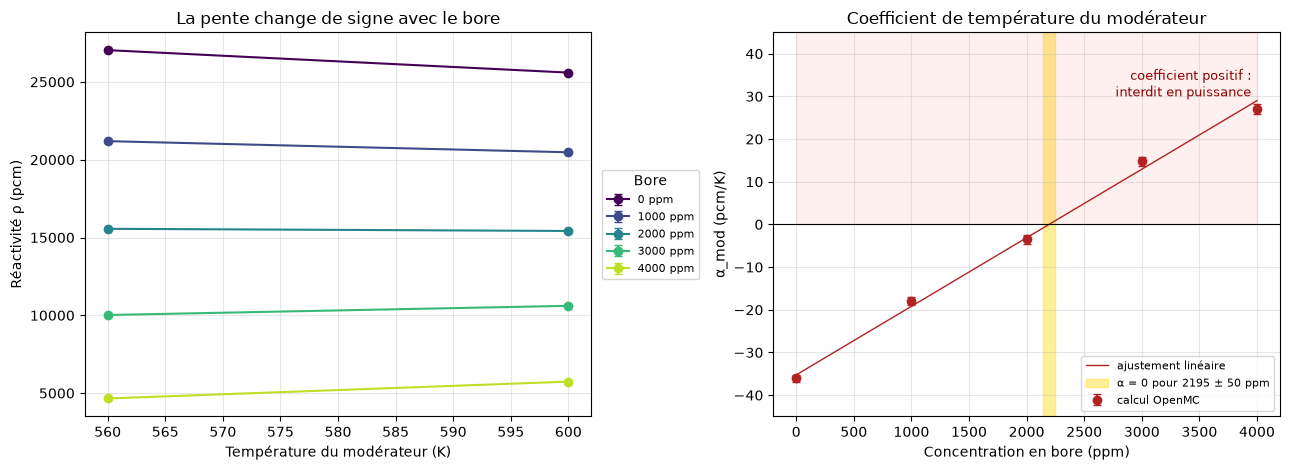

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

couleurs = plt.cm.viridis(np.linspace(0, 0.9, len(df_mtc)))
for (_, ligne), couleur in zip(df_mtc.iterrows(), couleurs):
    ax1.errorbar([T_BAS, T_HAUT], [ligne.rho_560K_pcm, ligne.rho_600K_pcm],
                 yerr=[ligne.sigma_560K, ligne.sigma_600K], fmt="o-", color=couleur, capsize=3,
                 label=f"{ligne.bore_ppm:.0f} ppm")
ax1.set_xlabel("Température du modérateur (K)")
ax1.set_ylabel("Réactivité ρ (pcm)")
ax1.set_title("La pente change de signe avec le bore")
ax1.legend(title="Bore", fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))

C_fin = np.linspace(0, 4000, 100)
ax2.errorbar(C, alpha, yerr=s_alpha, fmt="o", color="firebrick", capsize=3, label="calcul OpenMC")
ax2.plot(C_fin, np.polyval(coefs, C_fin), color="firebrick", lw=1, label="ajustement linéaire")
ax2.axhline(0, color="k", lw=0.8)
ax2.axvspan(C0 - sigma_C0_corrigee, C0 + sigma_C0_corrigee, color="gold", alpha=0.4,
            label=f"α = 0 pour {C0:.0f} ± {sigma_C0_corrigee:.0f} ppm")
ax2.fill_between(C_fin, 0, 45, color="red", alpha=0.06)
ax2.text(3950, 30, "coefficient positif :\ninterdit en puissance", ha="right", fontsize=9, color="darkred")
ax2.set_ylim(-45, 45)
ax2.set_xlabel("Concentration en bore (ppm)")
ax2.set_ylabel("α_mod (pcm/K)")
ax2.set_title("Coefficient de température du modérateur")
ax2.legend(loc="lower right", fontsize=8)

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "02b_coefficient_bore.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture.** Le coefficient passe d'environ −36 pcm/K sans bore à environ +27 pcm/K à 4000 ppm, et s'annule vers
2 200 ppm. L'ajustement linéaire décrit bien la tendance, mais son $\chi^2$ réduit (≈ 2,7) montre que les points s'en
écartent un peu plus que leurs barres d'erreur (jusqu'à 1,6σ), sans courbure nette : soit les incertitudes de
chaque point sont un peu sous-estimées, soit la relation n'est pas exactement linéaire. D'où l'incertitude élargie par
le facteur de Birge, plus honnête que l'incertitude brute.

## 2. Décomposition : densité ou température ?

Quand l'eau s'échauffe, deux choses changent en même temps :
1. sa **densité** baisse : il y a moins de molécules d'eau (et donc moins d'hydrogène et moins de bore) par cm³ ;
2. sa **température** monte : l'agitation des molécules modifie la thermalisation des neutrons, décrite par la loi
   S(α,β) de l'hydrogène lié, et le spectre thermique se décale vers les hautes énergies.

Le calcul permet ce qu'aucune expérience ne permet : séparer les deux effets. À 1000 ppm, on calcule
- l'effet de la **densité seule** : température des sections efficaces fixée à 580 K, densité de l'eau à 560 K puis
  à 600 K ;
- l'effet de la **température seule** : densité fixée à sa valeur à 580 K, température des sections efficaces à 560 K
  puis à 600 K.

Si les deux effets sont indépendants, leur somme doit redonner le coefficient total calculé en partie 1.

In [6]:
C_DECOMPOSITION = 1000
densite = {T: eau_boree(C_DECOMPOSITION, temperature=T).density for T in (T_BAS, 580.0, T_HAUT)}

alpha_densite = pente(
    reactivite("densite_seule_bas", bore_ppm=C_DECOMPOSITION, t_moderateur=580.0, densite_moderateur=densite[T_BAS]),
    reactivite("densite_seule_haut", bore_ppm=C_DECOMPOSITION, t_moderateur=580.0, densite_moderateur=densite[T_HAUT]),
)
alpha_temperature = pente(
    reactivite("temperature_seule_bas", bore_ppm=C_DECOMPOSITION, t_moderateur=T_BAS, densite_moderateur=densite[580.0]),
    reactivite("temperature_seule_haut", bore_ppm=C_DECOMPOSITION, t_moderateur=T_HAUT, densite_moderateur=densite[580.0]),
)
ligne_totale = df_mtc[df_mtc.bore_ppm == C_DECOMPOSITION].iloc[0]
alpha_total = (ligne_totale.alpha_mod_pcm_par_K, ligne_totale.sigma_alpha)
somme = (alpha_densite[0] + alpha_temperature[0], np.hypot(alpha_densite[1], alpha_temperature[1]))

df_decomposition = pd.DataFrame(
    [("densité seule", *alpha_densite), ("température seule", *alpha_temperature),
     ("somme des deux", *somme), ("total (partie 1)", *alpha_total)],
    columns=["effet", "alpha_pcm_par_K", "sigma"],
)
df_decomposition.to_csv(DOSSIER_RESULTATS / "02b_decomposition.csv", index=False)
for _, l in df_decomposition.iterrows():
    print(f"{l.effet:20s} : {l.alpha_pcm_par_K:6.1f} ± {l.sigma:.1f} pcm/K")
ecart = somme[0] - alpha_total[0]
print(f"\nÉcart somme − total : {ecart:+.1f} pcm/K, soit {ecart / np.hypot(somme[1], alpha_total[1]):+.1f} σ")

densité seule        :  -19.5 ± 0.9 pcm/K
température seule    :   -1.2 ± 0.9 pcm/K
somme des deux       :  -20.8 ± 1.2 pcm/K
total (partie 1)     :  -17.9 ± 0.9 pcm/K

Écart somme − total : -2.9 pcm/K, soit -1.9 σ


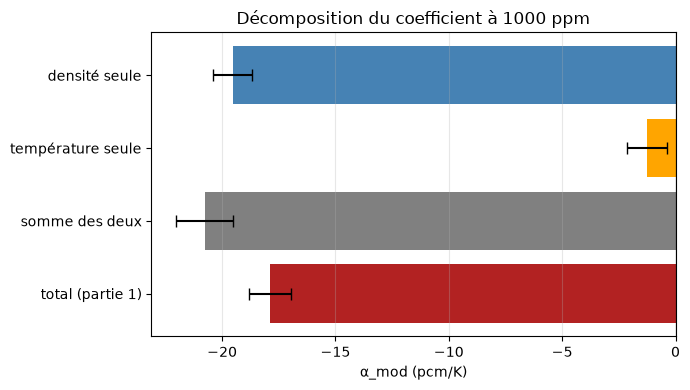

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(df_decomposition.effet, df_decomposition.alpha_pcm_par_K, xerr=df_decomposition.sigma, capsize=4,
        color=["steelblue", "orange", "gray", "firebrick"])
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("α_mod (pcm/K)")
ax.set_title(f"Décomposition du coefficient à {C_DECOMPOSITION} ppm")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "02b_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture.**
- L'effet de la **densité** représente l'essentiel du coefficient (environ −20 pcm/K).
- L'effet propre de la **température** est faible : environ −1 pcm/K, à peine plus grand que son incertitude.
- La somme des deux effets s'écarte du coefficient total d'environ 3 pcm/K, soit près de 2σ. C'est à la limite de la
  significativité : l'écart peut venir de la statistique, ou d'un **terme croisé**. Les deux effets ne sont pas
  rigoureusement additifs, car l'effet de la densité a été calculé avec des sections efficaces à 580 K, et celui de la
  température avec la densité à 580 K. Trancher demanderait plus de statistique ; la conclusion principale, le rôle
  dominant de la densité, n'en dépend pas.

## 3. Interprétation

### Pourquoi le coefficient est négatif sans bore : le REP est sous-modéré

À 0 ppm, l'effet est franchement négatif. Le réseau d'un REP est volontairement **sous-modéré** : il y a moins d'eau
que ce qui maximiserait k∞ (rapport de modération ≈ 1,7, notebook 01). Quand la densité de l'eau baisse, les neutrons
sont moins bien ralentis : ils passent plus de temps dans le domaine des résonances de l'U-238 et y sont davantage
capturés (le facteur antitrappe $p$ diminue). La réactivité baisse.

Dans un réseau **sur-modéré**, ce serait l'inverse : l'eau en excès capture plus de neutrons qu'elle n'en ralentit
utilement, et en retirer augmenterait la réactivité. Le choix du rapport de modération est donc avant tout un choix
de **sûreté**.

### Pourquoi le bore rend le coefficient positif

Le bore est dissous **dans l'eau**. Quand l'eau se dilate, elle emporte son bore avec elle : il y a moins d'atomes de
bore par cm³ dans le cœur, donc moins de captures, donc un gain de réactivité. Cet effet positif est proportionnel à
la quantité de bore, d'où la croissance à peu près **linéaire** de $\alpha_\text{mod}$ avec la concentration. Au-delà
de $C_0$, il l'emporte sur l'effet de modération.

### Le rôle de la température seule

À densité fixée, élever la température de l'eau ne change que peu la réactivité ici (environ −1 pcm/K, partie 2).
Plus chaude, l'eau thermalise les neutrons à une énergie un peu plus élevée : le spectre thermique se durcit. Ce
durcissement réduit à la fois les absorptions dans le bore et dans l'U-235 (sections efficaces en $1/v$), deux effets
de signes opposés sur la réactivité ; il est plausible qu'ils se compensent en grande partie, mais nos calculs ne les
séparent pas. **C'est la densité qui fait l'essentiel du coefficient.**

### Conséquences pour l'exploitation

- En puissance, le coefficient de température du modérateur doit rester **négatif** : cela **limite la concentration
  en bore** admissible. D'où l'usage de **poisons consommables** (gadolinium mélangé à l'UO₂ de certains crayons) pour
  compenser l'excès de réactivité du combustible neuf sans trop borer l'eau.
- Au fil du cycle, le bore est progressivement dilué : le coefficient devient de plus en plus négatif. En fin de cycle
  (bore presque nul), il est à son plus négatif, ce qui accentue certains transitoires de refroidissement (rupture de
  tuyauterie vapeur, par exemple), étudiés dans les analyses de sûreté.

### Limites de ce modèle

Il s'agit d'un **réseau infini de combustible neuf** : les valeurs de $C_0$ et de $\alpha_\text{mod}$ ne sont pas celles
d'un cœur réel. Dans un cœur, la baisse de densité augmente aussi les **fuites** de neutrons, ce qui ajoute un effet
négatif ; le plutonium formé au cours du cycle et les produits de fission modifient aussi le spectre. Les tendances
(signe à faible bore, croissance avec le bore, rôle dominant de la densité) restent en revanche celles d'un REP.

## 4. Bilan

- Sans bore, le coefficient de température du modérateur est nettement **négatif** : le réseau est sous-modéré.
- Le bore dissous le rend **moins négatif**, à peu près linéairement, jusqu'à l'annuler vers $C_0$ ; au-delà, il est
  positif, ce qui est interdit en puissance.
- L'effet vient presque entièrement de la **densité** de l'eau ; l'effet propre de sa température est faible
  (environ −1 pcm/K à 1000 ppm).

**Suite** : notebook 02c, coefficient de température du combustible (effet Doppler).

## Sources

- Documentation OpenMC 0.16 : `openmc.model.borated_water`, `openmc.data.water_density`
  (formulation IAPWS-IF97 de l'eau, région liquide), <https://docs.openmc.org/>.
- P. Reuss, *Précis de neutronique*, EDP Sciences : coefficients de température, sous-modération.